# Part 0 — meet the stock-month dataset

Start here before feature selection. We want to understand the observations,
return calendar, available universe, and what happened in the training years.
No predictive model is fitted and no feature list is chosen.

The assignment describes factor measurements available at a snapshot and a
**forward one-month simple return**. Our charts use earned-return months so that
January 2000 appears in January 2000, although its snapshot is December 1999.
The test file is loaded for structural auditing only in this notebook.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

# Locate the shared module without a machine-specific path.
search_roots = [Path.cwd(), *Path.cwd().parents]
FOUNDATION = next(
    candidate
    for base in search_roots
    for candidate in [
        base,
        base / 'part0_data_and_benchmark',
        base / '11_mlfactor_long_only_project_2026' / 'part0_data_and_benchmark',
    ]
    if (candidate / 'pipeline.py').is_file()
)
if str(FOUNDATION) not in sys.path:
    sys.path.insert(0, str(FOUNDATION))
from pipeline import (
    TARGET, FEATURES, FEATURE_INFO, project_root, load_panel, panel_audit,
    return_month, equal_weights, portfolio_returns, performance,
)
ROOT = project_root(FOUNDATION)
OUT = FOUNDATION / 'outputs'
FIGURES = OUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_rows', 25)

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / (name + '.png'), dpi=160, bbox_inches='tight')
    fig.savefig(FIGURES / (name + '.svg'), bbox_inches='tight')
    plt.show()

## 1. Check the files and the calendar

The number of rows is stocks times months, allowing membership to change.
Missing stock-months do not mean missing cells: a stock can simply be absent from
that month's universe. The audit fails rather than silently filling values.

In [2]:
train = load_panel('train', ROOT)
test_structure = load_panel('test', ROOT)
audit = pd.DataFrame({'training': panel_audit(train), 'testing': panel_audit(test_structure)})
display(audit)
audit.to_csv(OUT / 'dataset_audit.csv')
assert train.date.max() < test_structure.date.min()
assert set(return_month(train.date.unique())).isdisjoint(return_month(test_structure.date.unique()))
print('Securities appearing in both files:', len(set(train.stock_id) & set(test_structure.stock_id)))
print('All remaining asset-return charts use training rows only.')
del test_structure

example = train.iloc[0]
display(Markdown(
    f"For stock **{int(example.stock_id)}**, snapshot **{example.date:%Y-%m-%d}** "
    f"has a forward return of **{example[TARGET]:.1%}**, earned in "
    f"**{return_month([example.date])[0]:%B %Y}**."
))
display(train[['date', 'stock_id', 'Fcf_Yld', 'Ev_Ebitda', TARGET]].head())

,training,testing
rows,140739,127740
columns,23,23
months,120,108
stocks,1204,1195
first_snapshot,1999-12-31 00:00:00,2009-12-31 00:00:00
last_snapshot,2009-11-30 00:00:00,2018-11-30 00:00:00
first_return_month,2000-01-31 00:00:00,2010-01-31 00:00:00
last_return_month,2009-12-31 00:00:00,2018-12-31 00:00:00
min_stocks_per_month,1054,1109
max_stocks_per_month,1196,1194


Securities appearing in both files: 1193
All remaining asset-return charts use training rows only.


For stock **1**, snapshot **1999-12-31** has a forward return of **-4.2%**, earned in **January 2000**.

,date,stock_id,Fcf_Yld,Ev_Ebitda,R1M_Usd
0,1999-12-31,1,0.63,0.57,-0.042
1,1999-12-31,2,0.28,0.97,0.461
2,1999-12-31,3,0.87,0.17,-0.118
3,1999-12-31,4,0.15,0.51,-0.051
4,1999-12-31,5,0.45,0.93,-0.093


## 2. Name the measurements before interpreting them

These are accounting, valuation, payout, and trading-activity characteristics.
There are no raw prices, market caps, sectors, or ticker names in these CSVs.
The dictionary follows [MLFactor's variable descriptions](https://www.mlfactor.com/data-description.html).
`Ocf_Ce` uses capital employed; the two asset-based operating-cash-flow ratios
have different denominators. Exact vendor formulas remain unavailable.

Values lie on a 100-point grid between 0.01 and 1.00, consistent with percentile
encoding. For example, a dividend-yield value of 0.90 describes a high relative
rank, not a 90% dividend yield. Rank transformations are discussed in the
[MLFactor preprocessing chapter](https://www.mlfactor.com/Data.html).

In [3]:
dictionary = pd.DataFrame(FEATURE_INFO, columns=['feature', 'family', 'underlying_characteristic'])
dictionary['stored_units'] = 'percentile-like rank, 0.01 to 1.00'
dictionary.to_csv(OUT / 'feature_dictionary.csv', index=False)
display(dictionary)
feature_summary = train[FEATURES].agg(['min', 'median', 'mean', 'std', 'max']).T
feature_summary['distinct_values'] = train[FEATURES].nunique()
feature_summary.to_csv(OUT / 'training_feature_summary.csv')
display(feature_summary.round(3))

,feature,family,underlying_characteristic,stored_units
0,Ocf_Toa,Cash flow,Operating cash flow / total operating assets,"percentile-like rank, 0.01 to 1.00"
1,Tot_Debt_Rev,Debt,Total debt / revenue,"percentile-like rank, 0.01 to 1.00"
2,Net_Debt,Debt,Net debt,"percentile-like rank, 0.01 to 1.00"
3,Total_Liabilities_Total_Assets,Debt,Total liabilities / total assets,"percentile-like rank, 0.01 to 1.00"
4,Share_Turn_3M,Trading activity,Average share turnover over 3 months,"percentile-like rank, 0.01 to 1.00"
5,Fcf_Tbv,Cash flow,Free cash flow / tangible book value,"percentile-like rank, 0.01 to 1.00"
6,Debtequity,Debt,Debt / equity,"percentile-like rank, 0.01 to 1.00"
7,Ocf_Ce,Cash flow,Operating cash flow / capital employed,"percentile-like rank, 0.01 to 1.00"
8,Fcf_Yld,Valuation / payout,Free cash flow yield,"percentile-like rank, 0.01 to 1.00"
9,Ocf_Tbv,Cash flow,Operating cash flow / tangible book value,"percentile-like rank, 0.01 to 1.00"


,min,median,mean,std,max,distinct_values
Ocf_Toa,0.01,0.5,0.502,0.289,1.0,100
Tot_Debt_Rev,0.01,0.5,0.502,0.289,1.0,100
Net_Debt,0.01,0.5,0.502,0.288,1.0,100
Total_Liabilities_Total_Assets,0.01,0.5,0.501,0.289,1.0,100
Share_Turn_3M,0.01,0.5,0.500,0.288,1.0,100
Fcf_Tbv,0.01,0.5,0.502,0.289,1.0,100
Debtequity,0.01,0.5,0.498,0.285,1.0,100
Ocf_Ce,0.01,0.5,0.502,0.289,1.0,100
Fcf_Yld,0.01,0.5,0.498,0.287,1.0,100
Ocf_Tbv,0.01,0.5,0.502,0.288,1.0,100


## 3. What happened across the training universe?

The top-right panel compounds an equal capital allocation across every available
stock each month. The bottom-right bands instead show individual-stock return
quantiles within each month. Those bands are descriptive distributions, not
investable portfolios. Wide bands mean stocks had very different experiences.

The benchmark contains every stock available at its snapshot, including stocks
that do not survive to the last training month. Raw returns are retained.

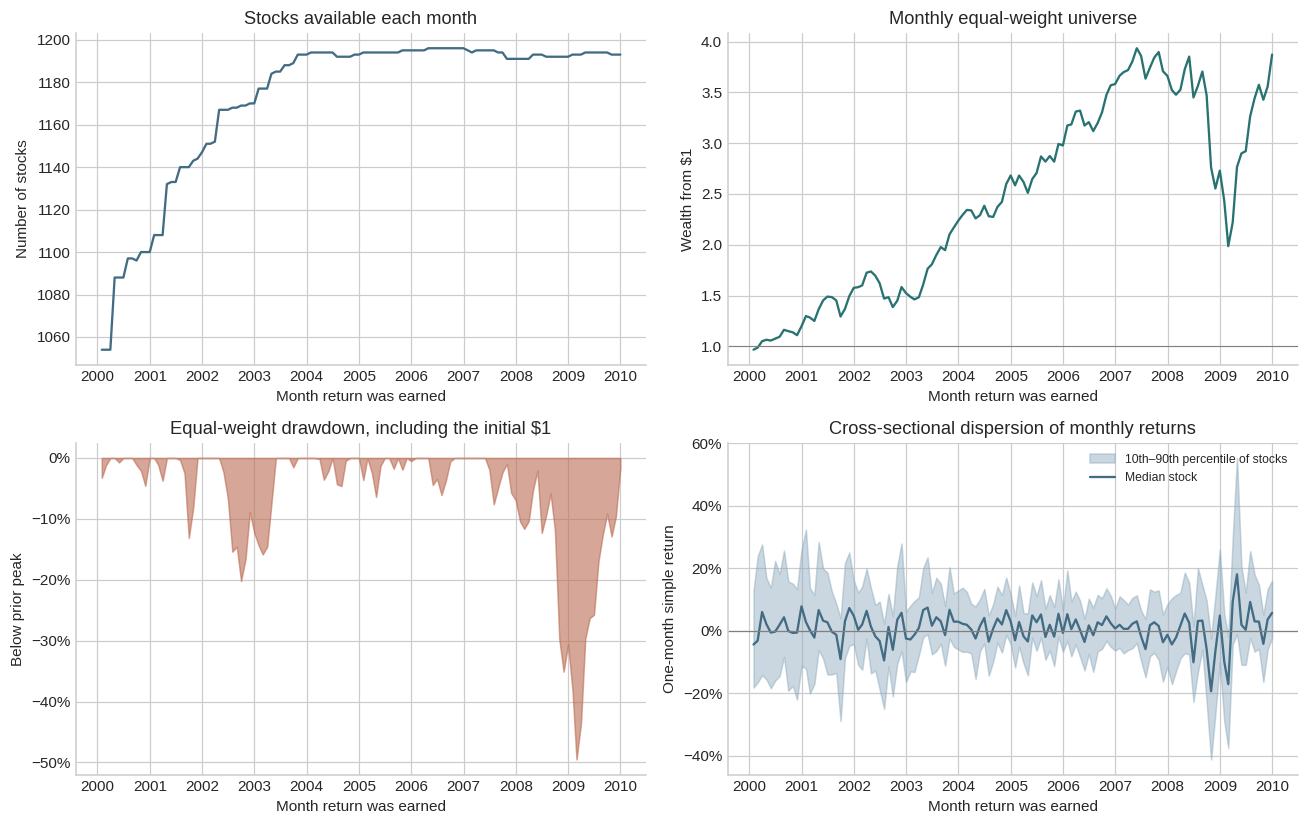

Training equal-weight statistics:


,value
months,120.000000
total_return,2.871932
cagr,0.144966
annualized_arithmetic_mean,0.155999
annualized_log_growth,0.135375
annualized_volatility,0.199173
sharpe,0.783231
max_drawdown,-0.495110
best_month,0.246085
worst_month,-0.204332


In [4]:
training_book = portfolio_returns(train)
training_book.to_csv(OUT / 'training_equal_weight_monthly.csv')
groups = train.groupby('date')[TARGET]
quantiles = groups.quantile([0.1, 0.5, 0.9]).unstack()
quantiles.index = return_month(quantiles.index)
counts = train.groupby('date').size()
counts.index = return_month(counts.index)
fig, axes = plt.subplots(2, 2, figsize=(12, 7.6))
axes[0, 0].plot(counts.index, counts.values, color='#426b84')
axes[0, 0].set(title='Stocks available each month', ylabel='Number of stocks')
axes[0, 1].plot(training_book.index, training_book.wealth, color='#287271')
axes[0, 1].axhline(1, color='gray', lw=0.7)
axes[0, 1].set(title='Monthly equal-weight universe', ylabel='Wealth from $1')
axes[1, 0].fill_between(training_book.index, training_book.drawdown.to_numpy(), 0, color='#bc6c53', alpha=0.6)
axes[1, 0].set(title='Equal-weight drawdown, including the initial $1', ylabel='Below prior peak')
axes[1, 0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1, 1].fill_between(quantiles.index, quantiles[0.1].to_numpy(), quantiles[0.9].to_numpy(), color='#8aa8bb', alpha=0.45, label='10th–90th percentile of stocks')
axes[1, 1].plot(quantiles.index, quantiles[0.5], color='#426b84', label='Median stock')
axes[1, 1].axhline(0, color='gray', lw=0.8)
axes[1, 1].set(title='Cross-sectional dispersion of monthly returns', ylabel='One-month simple return')
axes[1, 1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1, 1].legend(fontsize=8)
for ax in axes.flat:
    ax.set_xlabel('Month return was earned')
save_figure(fig, '01_training_overview')
print('Training equal-weight statistics:')
display(performance(training_book.simple_return).to_frame('value'))

## 4. A few individual-stock paths

Here we compound the supplied returns for six stocks with complete training
coverage, taking the lowest security IDs. We do not select winners or use the
test file. This is a reproducible illustration, not a representative sample or
a strategy. Complete-history screening is NOT used for the benchmark.

These are indexed wealth paths from provided returns, not observed price charts.
A logarithmic vertical axis makes equal percentage changes comparable at different
wealth levels. It does not change how returns are calculated.

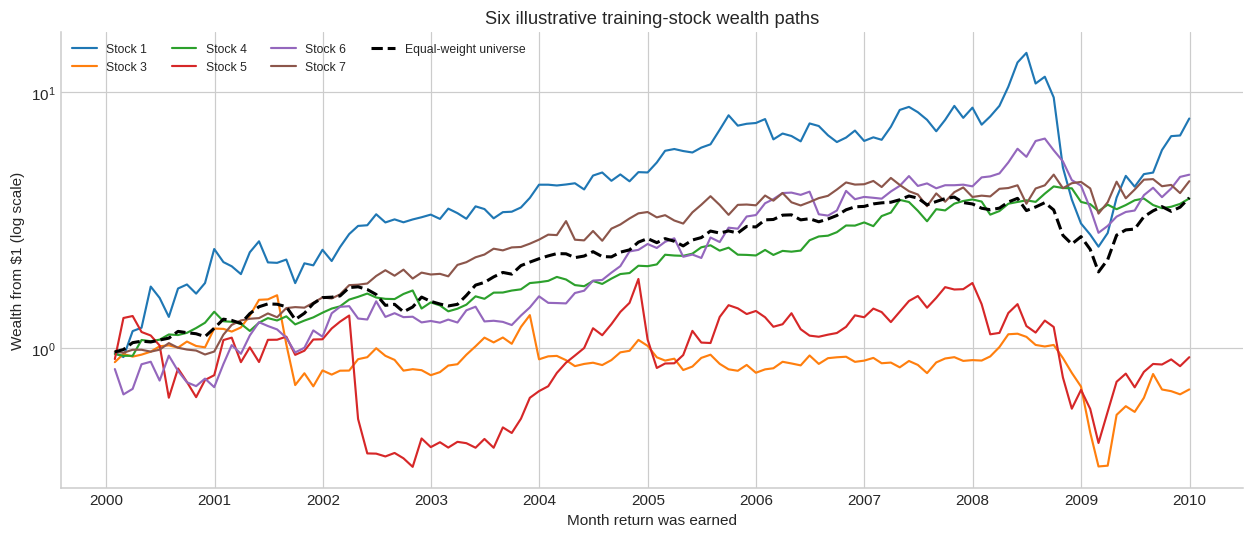

Illustrative IDs: [1, 3, 4, 5, 6, 7]


In [5]:
coverage = train.groupby('stock_id').date.nunique()
illustrative_ids = coverage[coverage.eq(train.date.nunique())].sort_index().index[:6]
stock_returns = train[train.stock_id.isin(illustrative_ids)].pivot(index='date', columns='stock_id', values=TARGET)
stock_returns.index = return_month(stock_returns.index)
assert not stock_returns.isna().any().any()
stock_wealth = (1 + stock_returns).cumprod()
stock_wealth.to_csv(OUT / 'illustrative_training_stock_wealth.csv')
fig, ax = plt.subplots(figsize=(11.5, 5))
for sid in illustrative_ids:
    ax.plot(stock_wealth.index, stock_wealth[sid], lw=1.4, label=f'Stock {sid}')
ax.plot(training_book.index, training_book.wealth, color='black', lw=2, linestyle='--', label='Equal-weight universe')
ax.set_yscale('log')
ax.set(title='Six illustrative training-stock wealth paths', ylabel='Wealth from $1 (log scale)', xlabel='Month return was earned')
ax.legend(ncol=4, fontsize=8)
save_figure(fig, '02_training_stock_paths')
print('Illustrative IDs:', list(illustrative_ids))

## 5. Examine extreme returns before choosing a modeling target

The first histogram includes the entire range and uses a log count axis. The
second zooms to the central 98% of observations for readability. Zooming does
not remove rows from the portfolio calculation. A return of 27 is +2,700%, not
27%. Such observations deserve source investigation; size alone does not prove
an error. The dataset cannot tell us the relevant corporate-action history.

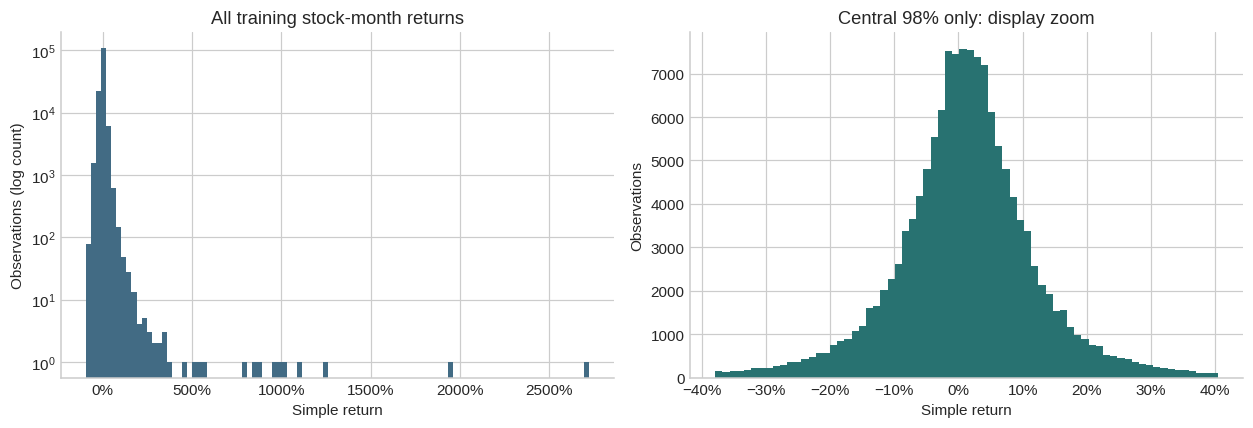

146 stock-months with |return| > 100% account for 50.0% of squared returns.
Training range: -92.2% to 2723.3%.


,date,stock_id,R1M_Usd,return_month
139765,2009-11-30,221,27.233,2009-12-31
17673,2001-04-30,212,19.556,2001-05-31
33832,2002-06-30,296,12.500,2002-07-31
4338,2000-04-30,95,11.105,2000-05-31
134427,2009-06-30,862,10.328,2009-07-31
137832,2009-09-30,683,9.914,2009-10-31
131297,2009-04-30,108,9.703,2009-05-31
106349,2007-07-31,199,8.664,2007-08-31
93116,2006-08-31,113,8.477,2006-09-30
36121,2002-08-31,248,7.846,2002-09-30


In [6]:
r = train[TARGET]
lo, hi = r.quantile([0.01, 0.99])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
axes[0].hist(r, bins=100, color='#426b84', log=True)
axes[0].set(title='All training stock-month returns', xlabel='Simple return', ylabel='Observations (log count)')
axes[1].hist(r[r.between(lo, hi)], bins=70, color='#287271')
axes[1].set(title='Central 98% only: display zoom', xlabel='Simple return', ylabel='Observations')
for ax in axes:
    ax.xaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig, '03_training_return_distribution')
extreme = r.abs().gt(1)
tail_share = float(r[extreme].pow(2).sum() / r.pow(2).sum())
print(f'{int(extreme.sum()):,} stock-months with |return| > 100% account for {tail_share:.1%} of squared returns.')
print(f'Training range: {r.min():.1%} to {r.max():.1%}.')
extremes = train.loc[r.abs().nlargest(10).index, ['date', 'stock_id', TARGET]].copy()
extremes['return_month'] = return_month(extremes.date)
extremes.to_csv(OUT / 'training_extreme_observations.csv', index=False)
display(extremes)

## 6. Related characteristics are visible without selecting features

The feature correlation picture asks what moves together, not what predicts
future returns. The three turnover windows are nearly duplicate measurements.
Other groups describe related debt or cash-flow characteristics. This is a
reason to consider simple composites later; it does not establish better
strategy performance. We stop short of PCA, selection scores, or model fitting.

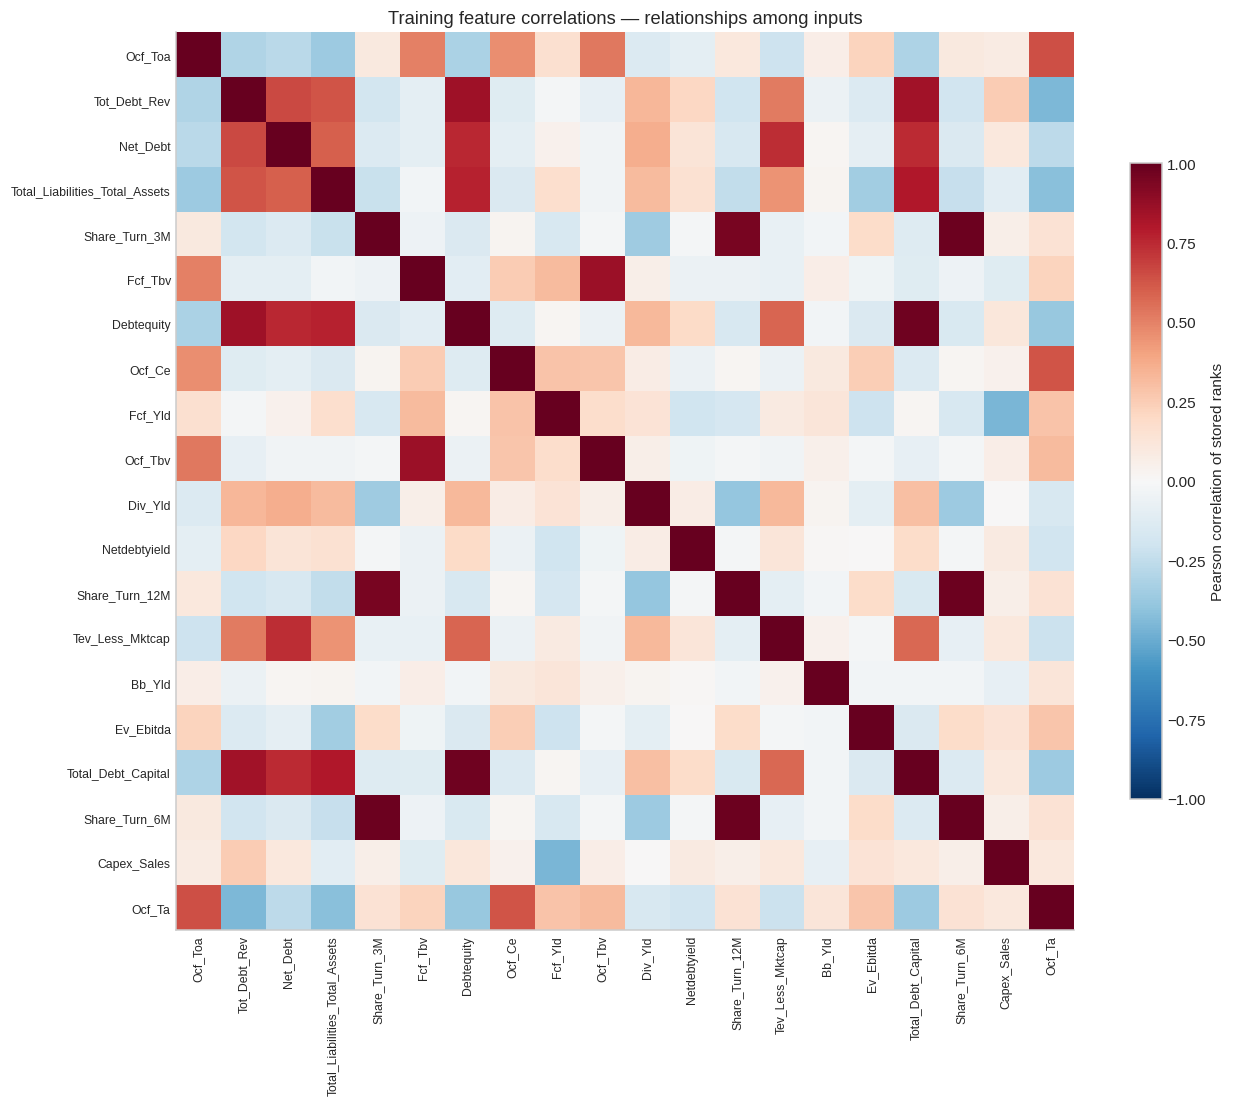

,Share_Turn_3M,Share_Turn_6M,Share_Turn_12M
Share_Turn_3M,1.000,0.979,0.948
Share_Turn_6M,0.979,1.000,0.977
Share_Turn_12M,0.948,0.977,1.000


In [7]:
fig, ax = plt.subplots(figsize=(12, 10))
corr = train[FEATURES].corr()
image = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=8)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
ax.grid(False)
ax.set_title('Training feature correlations — relationships among inputs')
fig.colorbar(image, ax=ax, shrink=0.7, label='Pearson correlation of stored ranks')
save_figure(fig, '04_training_feature_correlations')
corr.to_csv(OUT / 'training_feature_correlations.csv')
turnover_cols = ['Share_Turn_3M', 'Share_Turn_6M', 'Share_Turn_12M']
display(corr.loc[turnover_cols, turnover_cols].round(3))

## 7. Record what was read

The manifest identifies the actual files and library versions for this run.
The project is not yet at a final model choice. Next, work through notebook 03,
where portfolio arithmetic gets its own independent checks.

The origin and limitations are explained in [01_dataset.md](01_dataset.md).
The class's larger goals remain in the [assignment notebook](../03_mlfactor_long_only_project.ipynb).

In [8]:
import hashlib
import json
import platform
import matplotlib

manifest = {
    'source_files': {
        path.name: {'sha256': hashlib.sha256(path.read_bytes()).hexdigest(), 'bytes': path.stat().st_size}
        for path in [ROOT / 'mlfactor_long_only_train.csv', ROOT / 'mlfactor_long_only_test.csv']
    },
    'python': platform.python_version(),
    'libraries': {'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__},
    'target': 'Forward one-month decimal simple return',
    'calendar': 'Snapshot month t; return earned in month t+1',
    'sources': [
        'https://www.mlfactor.com/notdata.html',
        'https://www.mlfactor.com/data-description.html',
        'https://www.mlfactor.com/Data.html',
    ],
}
(OUT / 'source_manifest.json').write_text(json.dumps(manifest, indent=2) + '\n')
print('Wrote source_manifest.json and the training exploration artifacts.')

Wrote source_manifest.json and the training exploration artifacts.
